# Historia 6 — Czy większa ufność daje szerszy przedział?


Użyjemy danych z Historii 1: **350 z 500 studentów** woli zajęcia online.

**Cel:** porównać przedziały ufności **90%, 95% i 99%**.

Sprawdzimy, jak zmienia się zakres wyników, gdy chcemy mieć większą ufność.

### Przygotowanie
Wczytujemy biblioteki potrzebne do obliczeń i wykresów.

In [10]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display

### Dane z ankiety
Zapisujemy tutaj dane z Historii 1, aby ten plik działał **samodzielnie**.

In [11]:
n1 = 500
online1 = 350
p1 = online1 / n1
se1 = np.sqrt(p1 * (1 - p1) / n1)

### Krok 1. Obliczamy przedziały dla trzech poziomów
Używamy tego samego wyniku ankiety, ale trzy razy zmieniamy poziom ufności. Wyniki zapisujemy w tabeli.

In [12]:
poziomy6 = [0.90, 0.95, 0.99]
wyniki6 = []
for poziom in poziomy6:
    z = stats.norm.ppf((1 + poziom) / 2)
    m = z * se1
    wyniki6.append({
        "Poziom ufności": f"{poziom:.0%}",
        "Dolna granica": p1 - m,
        "Górna granica": p1 + m,
        "Margines błędu (punkty procentowe)": 100 * m,
    })

tabela6 = pd.DataFrame(wyniki6)
display(tabela6.round(4))

,Poziom ufności,Dolna granica,Górna granica,Margines błędu (punkty procentowe)
0,90%,0.6663,0.7337,3.3709
1,95%,0.6598,0.7402,4.0167
2,99%,0.6472,0.7528,5.2789


### Krok 2. Tworzymy wykres
Rysujemy trzy odcinki. Dłuższy odcinek oznacza szerszy przedział ufności.

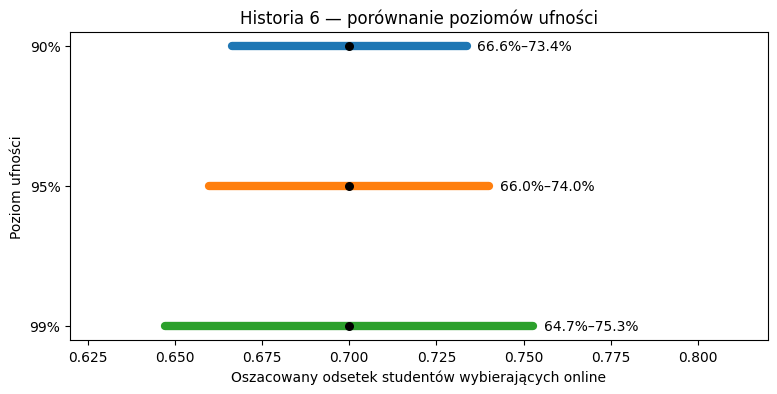

In [13]:
fig, ax = plt.subplots(figsize=(9, 4))
for i, wynik in enumerate(wyniki6):
    dol = wynik["Dolna granica"]
    gora = wynik["Górna granica"]
    ax.plot([dol, gora], [i, i], linewidth=6, solid_capstyle="round")
    ax.scatter([p1], [i], color="black", s=30, zorder=3)
    ax.text(gora + 0.003, i, f"{dol:.1%}–{gora:.1%}", va="center", fontsize=10)
ax.set_yticks(range(len(poziomy6)), [f"{p:.0%}" for p in poziomy6])
ax.set_xlim(0.62, 0.82)
ax.set(xlabel="Oszacowany odsetek studentów wybierających online",
       ylabel="Poziom ufności", title="Historia 6 — porównanie poziomów ufności")
ax.invert_yaxis()
plt.show()

### Wniosek
Im **wyższy poziom ufności**, tym **szerszy przedział**, jeżeli liczba ankietowanych pozostaje taka sama.